# 3.  Codificación de variables

Conjunto de datos: titanic (incluido en seaborn)

Este conjunto de datos es excelente para trabajar con variables categóricas.

In [8]:
# Importar librerías necesarias
import pandas as pd
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, OneHotEncoder

In [9]:
# Cargar el conjunto de datos
data = sns.load_dataset('titanic')

In [10]:
# Visualizar las primeras filas
print("Conjunto de datos Titanic:")
data.head()

Conjunto de datos Titanic:


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [11]:
# Seleccionar columnas categóricas
categorical_cols = ['sex', 'embarked', 'class']

In [12]:
# Codificar con LabelEncoder
label_encoder = LabelEncoder()
data['sex_label'] = label_encoder.fit_transform(data['sex'])

In [13]:
# Codificar con OneHotEncoder
onehot_encoder = pd.get_dummies(data['embarked'], prefix='embarked')

In [14]:
# Combinar con el conjunto original
data = pd.concat([data, onehot_encoder], axis=1)

# Ejercicios
Contesta las siguientes preguntas. Para cada pregunta, deberás escribir código que demostrará cómo llegaste al resultado. Crea gráficas en donde veas correcto.

### 1. ¿Qué diferencias encuentras entre LabelEncoder y OneHotEncoder?

In [15]:
print("sex original:", data['sex'].unique(), "-> LabelEncoder:", label_encoder.transform(label_encoder.classes_), label_encoder.classes_)
print()
print("LabelEncoder (una sola columna de enteros):")
print(data[['sex', 'sex_label']].head())
print()
print("get_dummies / One-Hot (una columna binaria por categoría):")
print(data[['embarked', 'embarked_C', 'embarked_Q', 'embarked_S']].head())

sex original: <StringArray>
['male', 'female']
Length: 2, dtype: str -> LabelEncoder: [0 1] ['female' 'male']

LabelEncoder (una sola columna de enteros):
      sex  sex_label
0    male          1
1  female          0
2  female          0
3  female          0
4    male          1

get_dummies / One-Hot (una columna binaria por categoría):
  embarked  embarked_C  embarked_Q  embarked_S
0        S       False       False        True
1        C        True       False       False
2        S       False       False        True
3        S       False       False        True
4        S       False       False        True


**Respuesta:**

| | LabelEncoder | OneHotEncoder |
|---|---|---|
| Salida | 1 columna de enteros (0, 1, 2…) | 1 columna binaria por categoría |
| Orden implícito | Sí: introduce un orden/distancia artificial entre categorías | No: las categorías son independientes |
| Dimensionalidad | No aumenta | Aumenta con el número de categorías |
| Uso recomendado | Variable objetivo, categorías ordinales o árboles | Variables nominales en modelos lineales, KNN, redes neuronales |

### 2. Crea una gráfica de barras comparando las frecuencias de 'sex' antes y después de la codificación con LabelEncoder.

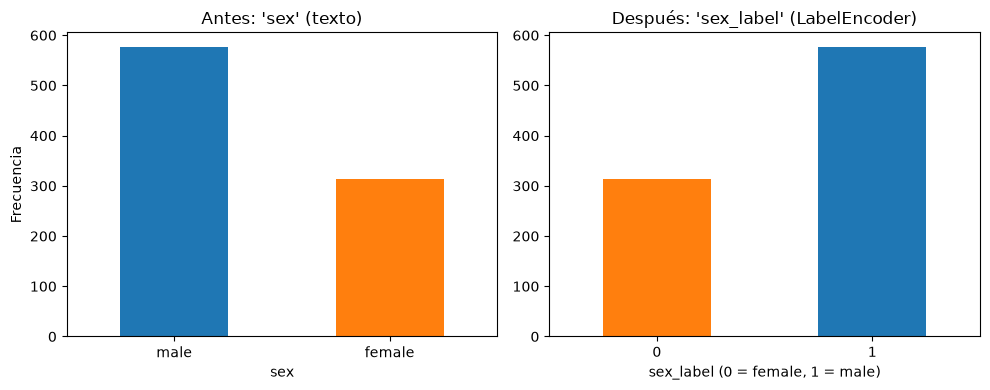

In [16]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

data['sex'].value_counts().plot(kind='bar', ax=axes[0], color=['tab:blue', 'tab:orange'], rot=0)
axes[0].set_title("Antes: 'sex' (texto)")
axes[0].set_ylabel('Frecuencia')

data['sex_label'].value_counts().sort_index().plot(kind='bar', ax=axes[1], color=['tab:orange', 'tab:blue'], rot=0)
axes[1].set_title("Después: 'sex_label' (LabelEncoder)")
axes[1].set_xlabel('sex_label (0 = female, 1 = male)')

plt.tight_layout()
plt.show()

Las frecuencias son las mismas (314 mujeres y 577 hombres); la codificación solo cambia la etiqueta de cada categoría por un entero.

### 3. Utiliza OneHotEncoder para codificar la columna 'class'. ¿Qué ventajas tiene este enfoque frente a LabelEncoder?

In [17]:
# OneHotEncoder de sklearn sobre la columna 'class'
ohe = OneHotEncoder(sparse_output=False)
class_ohe = ohe.fit_transform(data[['class']])
class_ohe = pd.DataFrame(class_ohe, columns=ohe.get_feature_names_out(['class']), index=data.index)
print(class_ohe.head())
print()
print("Categorías:", list(ohe.categories_[0]))

   class_First  class_Second  class_Third
0          0.0           0.0          1.0
1          1.0           0.0          0.0
2          0.0           0.0          1.0
3          1.0           0.0          0.0
4          0.0           0.0          1.0

Categorías: ['First', 'Second', 'Third']


**Ventajas frente a LabelEncoder:** One-Hot no impone un orden numérico artificial entre las categorías (con LabelEncoder el modelo podría interpretar que `Third` > `Second` > `First` por los enteros asignados, o que la "distancia" entre categorías es significativa). Cada categoría se trata como independiente, lo que evita sesgos en modelos basados en distancia o en coeficientes (regresión lineal/logística, KNN, redes neuronales). Su desventaja es que aumenta el número de columnas (aquí de 1 a 3).

Nota: `class` es en realidad ordinal (First > Second > Third), así que una codificación ordinal también sería válida; One-Hot es la opción más segura si no se quiere suponer un orden.

### 4. Si quisieras aplicar un modelo de aprendizaje automático, ¿qué tipo de codificación elegirías para las variables categóricas? Explica tu respuesta.

**Respuesta:** depende del tipo de variable y del modelo:

- **Variables nominales** (`embarked`, `sex` con más de dos categorías, etc.): **One-Hot Encoding** para modelos lineales, KNN, SVM o redes neuronales, porque no introduce un orden falso. Con pocas categorías (como aquí) el aumento de columnas es manejable; con muchas categorías conviene otra técnica (target encoding, agrupar categorías raras).
- **Variables ordinales** (`class`: First < Second < Third): codificación ordinal (con `OrdinalEncoder` y el orden explícito), que conserva la información de jerarquía en una sola columna.
- **Variables binarias** (`sex`): basta una columna 0/1 (LabelEncoder o `drop_first`).
- **Modelos de árboles** (Random Forest, Gradient Boosting) toleran mejor la codificación por etiqueta, pero One-Hot sigue siendo una opción segura.
- **LabelEncoder** se reserva para la variable objetivo, no para las variables de entrada.

Para el Titanic con un modelo de regresión logística, usaría One-Hot en `embarked`, ordinal en `class` y 0/1 en `sex`.